# Sensitivity Analysis on Training Size for Parametric State Estimation with Shallow Decoder Network on TRIGA-MC data
This notebook implements a Sensitivity Analysis for Shallow Decoder Network (SDN) aimed at reconstructing the state (the total flux $\Phi$) of a TRIGA reactor based on its operational parameters (position of the SHIM and REG control rod) and few local measurements.

This notebook will investigate:
1. the influence of the size of the training and validation set of data on the reconstruction of the state vector.

For the following discussion, let $\mathbf{f}$ be the SDN model, $\mathbf{y}$ the input measures, $\boldsymbol{\mu}$ the parameters and $\mathbf{u}$ the output state of the reactor, let $\mathbf{v}$ be the low-dimensional representation of the state vector $\mathbf{u}$, obtained by projecting the high-dimensional flux data on the SVD modes, and let $\mathbb{U}$ be the matrix of SVD modes.

This notebook can load MonteCarlo data either with low or high statistics (the uncertainty is higher for low statistics, two times higher).

Let us import the data

In [1]:
# _stats = '_lowstats'
_stats = '_highstats'

import numpy as np
_tmp = np.load(f'../Data/flux_data{_stats}.npz', allow_pickle=True)

snaps = _tmp['flux']
params = _tmp['params']
centroids = _tmp['centroids']

del _tmp

Let us extract the test set and plot the parameter space

Text(0, 0.5, 'REG Position')

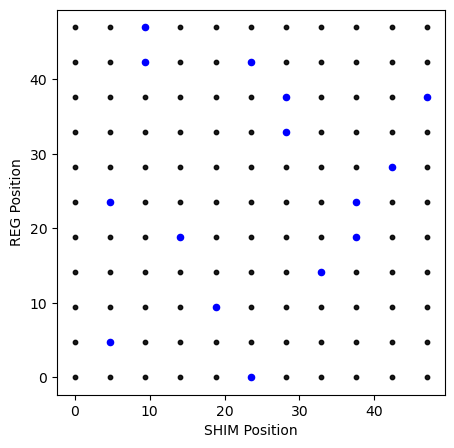

In [2]:
import numpy as np
from scipy.stats import qmc
from scipy.spatial import cKDTree

# Define LHS sampler in 2D
seedtest = 42  # Set a seed for reproducibility
sampler = qmc.LatinHypercube(d=2, seed=seedtest)

# Number of points to sample
test_size = 0.15
n_test = int(test_size * len(params))  # 15% of the total data

# Generate LHS points in the unit square
lhs_points = sampler.random(n=n_test)

# Scale the LHS points to the range of your data
min_vals = np.min(params, axis=0)
max_vals = np.max(params, axis=0)

# Scale LHS to data range
scaled_lhs_points = qmc.scale(lhs_points, min_vals, max_vals)

tree = cKDTree(params)
distances, test_indices = tree.query(scaled_lhs_points, k=1)
test_indices = np.unique(test_indices)

# Extract the train and validation indices
all_indices = np.arange(len(params))
train_val_indices = np.setdiff1d(all_indices, test_indices)

import matplotlib.pyplot as plt

fig , ax = plt.subplots(figsize=(5, 5))

ax.scatter(params[:, 0], params[:, 1], s=10, c='k', alpha=0.9)
ax.scatter(params[test_indices, 0], params[test_indices, 1], s=20, c='b', label='LHS Sampled Points')

ax.set_xlabel(r'SHIM Position')
ax.set_ylabel(r'REG Position')

Let us fix the architecture of the SDN following the other Sensitivity Analysis notebooks on the number of sensors to use.

In [3]:
xmin, xmax = -20, 20
ymin, ymax = -20, 20
zmin, zmax = 20.0, 50.0

mask = (
    (centroids[:, 0] >= xmin) & (centroids[:, 0] <= xmax) &
    (centroids[:, 1] >= ymin) & (centroids[:, 1] <= ymax) &
    (centroids[:, 2] >= zmin) & (centroids[:, 2] <= zmax)
)

cell_indices = np.where(mask)[0] 
non_cell_indices = np.setdiff1d(np.arange(centroids.shape[0]), cell_indices)

num_senss = 3
idx_sens_locs = np.random.choice(cell_indices, num_senss, replace=False)

## Influence of the training set size on the reconstruction of the state vector
We will investigate the influence of the size of the training set (validation is always 20% of it) on the reconstruction of the state vector, the influence of the position will be investigated by performing different repetead numerical experiments with different seed number.

Let us indicate with $\mathbf{f}_\gamma$ the SDN model trained with $\gamma$ as the size of the training set whose output is $\mathbf{u}_\gamma = \mathbb{U}\mathbf{f}_\gamma(\mathbf{y}, \boldsymbol{\mu})$.

In [ ]:
from IPython.display import clear_output as clc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import randomized_svd
import torch

from utils.sdn import ShallowDecoderNetwork, MyDataset, fit

# Set the device
device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')

compressive_training = True

max_flux = snaps.max()
test_data  = snaps[:, test_indices] / max_flux

rank = 10

def run_sensitivity_analysis(gamma):


    print(f'Running sensitivity analysis with training set size: {gamma*100}%')

    # Select only some indices for training and validation
    available_indices = np.random.choice(train_val_indices, size=int(gamma * len(train_val_indices)), replace=False)

    train_indices, valid_indices = train_test_split(available_indices, train_size=0.8) # validation is 20% of the training set

    # Define parameters for training, testing, and validation sets
    train_params = params[train_indices]
    test_params  = params[test_indices]
    valid_params = params[valid_indices]

    # Define snapshots for training, testing, and validation sets
    train_data = snaps[:, train_indices] / max_flux
    valid_data = snaps[:, valid_indices] / max_flux

    # Perform SVD
    modes, _, _ = randomized_svd(train_data, n_components=rank, n_iter='auto')

    _test_rec = np.dot(modes[:,:rank], np.dot(modes[:,:rank].T, test_data))

    err_svd = np.linalg.norm(_test_rec - test_data) / np.linalg.norm(test_data)

    # Create the input data for the SDN
    train_input = np.concatenate([train_data[idx_sens_locs], train_params.T], axis=0)
    test_input  = np.concatenate([test_data[idx_sens_locs],  test_params.T],  axis=0)
    valid_input = np.concatenate([valid_data[idx_sens_locs], valid_params.T], axis=0)

    # Define the scaler for the input data
    input_scaler = MinMaxScaler()
    input_scaler.fit(train_input.T)

    # Scale the input data
    train_input = input_scaler.transform(train_input.T).T
    test_input  = input_scaler.transform(test_input.T).T
    valid_input = input_scaler.transform(valid_input.T).T

    # Define the dataset for input and output
    train_dataset = MyDataset(torch.tensor(train_input.T, dtype=torch.float32).to(device), torch.tensor(train_data.T, dtype=torch.float32).to(device))
    test_dataset  = MyDataset(torch.tensor(test_input.T, dtype=torch.float32).to(device),  torch.tensor(test_data.T, dtype=torch.float32).to(device))
    valid_dataset = MyDataset(torch.tensor(valid_input.T, dtype=torch.float32).to(device), torch.tensor(valid_data.T, dtype=torch.float32).to(device))

    # Define the SDN model
    in_dim = train_input.shape[0]
    out_dim = rank if compressive_training else train_data.shape[0]
    pod_modes = torch.tensor(modes[:, :rank+1], dtype=torch.float32).to(device) if compressive_training else None

    sdn = ShallowDecoderNetwork(in_dim = in_dim, out_dim=out_dim, dropout=0.1, decoder_sizes=[350,400], pod_modes=pod_modes).to(device)

    fit(model=sdn, train_dataset=train_dataset, valid_dataset=valid_dataset, 
        batch_size=32, epochs=500, patience=30,
        optim=torch.optim.Adam, criterion=torch.nn.L1Loss(), lr=0.001, 
        verbose=True)
    
    # Evaluate the model
    sdn.freeze()

    return np.abs(sdn(test_dataset.X).cpu().detach().numpy() - test_data.T), err_svd, train_indices, valid_indices

num_rep_exp = 10
fractions = [0.15, 0.3, 0.5, 0.65, 0.8, 1]

errors = np.zeros((num_rep_exp, len(fractions), len(test_indices), snaps.shape[0]))
err_svd = np.zeros((num_rep_exp, len(fractions)))
train_indices = list()
valid_indices = list()

for kk in range(num_rep_exp):
    print(f'Experiment {kk+1}/{num_rep_exp}')
    np.random.seed(kk)  # Optional: different seed per experiment, but reproducible
    for ii, gamma in enumerate(fractions):
        errors[kk, ii], err_svd_, train_indices_, valid_indices_ = run_sensitivity_analysis(gamma)

        # Store the errors and indices
        err_svd[kk, ii] = err_svd_
        train_indices.append(train_indices_)
        valid_indices.append(valid_indices_)

    clc()

### Comparison of the results
Let us compare the results of the sensitivity analysis with and without the operational parameters. 

At first, let us store the residual fields in `npz` files.

In [ ]:
import os

path_res = os.path.join(os.getcwd(), '../Results/SensitivityAnalysis/TrainSize/')
os.makedirs(path_res, exist_ok=True)

np.savez_compressed(path_res + f'sensitivity_analysis{_stats}.npz',
                   errors=errors,
                   fractions=fractions,
                   err_svd=err_svd
                   )

import pickle

with open(path_res + f'train_valid_indices{_stats}.pkl', 'wb') as f:
    pickle.dump({
        'train_indices': train_indices,
        'valid_indices': valid_indices
    }, f)
    
# errors = np.load(path_res + f'sensitivity_analysis{_stats}.npz', allow_pickle=True)
# errors = errors['errors'].item()

Since different numerical experiments are performed we can compute the mean and standard deviation of the errors.

Let $\mathbf{u}_\gamma(\boldsymbol{\mu})$ be the reconstructed state vector with $\gamma$ training data and operational parameters $\boldsymbol{\mu}$, we can compute the average relative error as follows:
$$ 
\varepsilon_\gamma^k = \frac{1}{N_s^{test}} \sum_{i=1}^{N_s^{test}} \frac{\| \mathbf{u}_\gamma(\boldsymbol{\mu}_i) - \mathbf{u}(\boldsymbol{\mu}_i)\|_2}{\| \mathbf{u}(\boldsymbol{\mu}_i)\|_2}
$$
where $N_s^{test}$ is the number of operational parameters for the numerical experiment $k$. With $\varepsilon_M$ we indicate the mean over the numerical experiments.

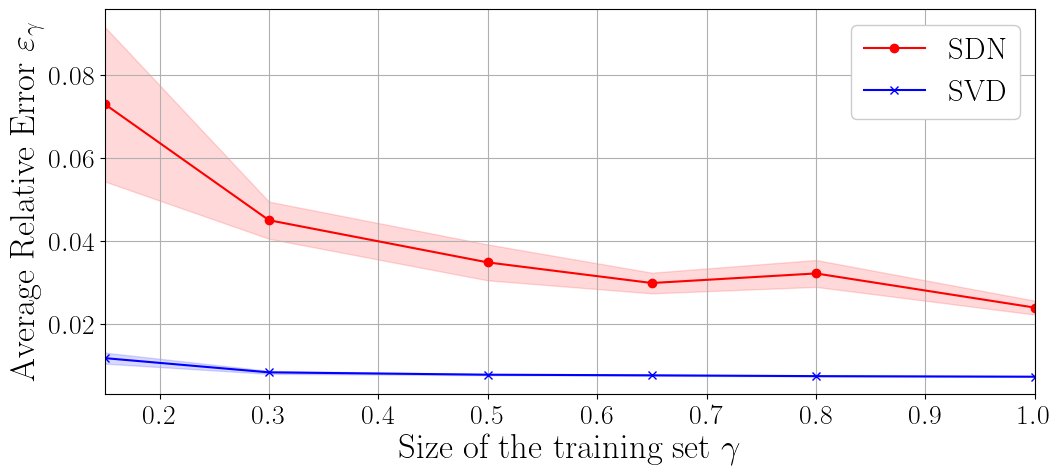

In [7]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams.update({
  "text.usetex": True,
  "font.family": "serif"
})

rcParams['text.latex.preamble'] = r'\usepackage{amssymb} \usepackage{amsmath} \usepackage{amsthm} \usepackage{mathtools}'

fig, ax = plt.subplots(figsize=(12, 5))

mean_ = (np.linalg.norm(errors, axis=-1) / np.linalg.norm(test_data, axis=0)).mean(axis=-1).mean(axis=0)
std_  = (np.linalg.norm(errors, axis=-1) / np.linalg.norm(test_data, axis=0)).mean(axis=-1).std(axis=0)

ax.plot(fractions, mean_, color='r', marker='o', label='SDN')
ax.fill_between(fractions, mean_ - std_, mean_ + std_, color='r', alpha=0.15)

ax.plot(fractions, err_svd.mean(axis=0), color='b', marker='x', label='SVD')
ax.fill_between(fractions, err_svd.mean(axis=0) - err_svd.std(axis=0), err_svd.mean(axis=0) + err_svd.std(axis=0), color='b', alpha=0.15)

ax.set_xlabel('Size of the training set $\gamma$', fontsize=25)
ax.set_ylabel(r'Average Relative Error $ \varepsilon_\gamma$', fontsize=25)
ax.grid()
ax.legend(framealpha=1, ncols=1, fontsize=22, loc='upper right')
ax.set_xlim(fractions[0], fractions[-1])
ax.tick_params(axis='both', which='major', labelsize=20)
fig.savefig(path_res + f'ave_rel_err_sensitivity{_stats}_{seedtest}.pdf', bbox_inches='tight', dpi=300)


Let us observe how the residual field, defined as $\mathbf{r}_M = |\mathbf{u} - \mathbf{u}_M|$, is spread over the core adopting a statistical approach.

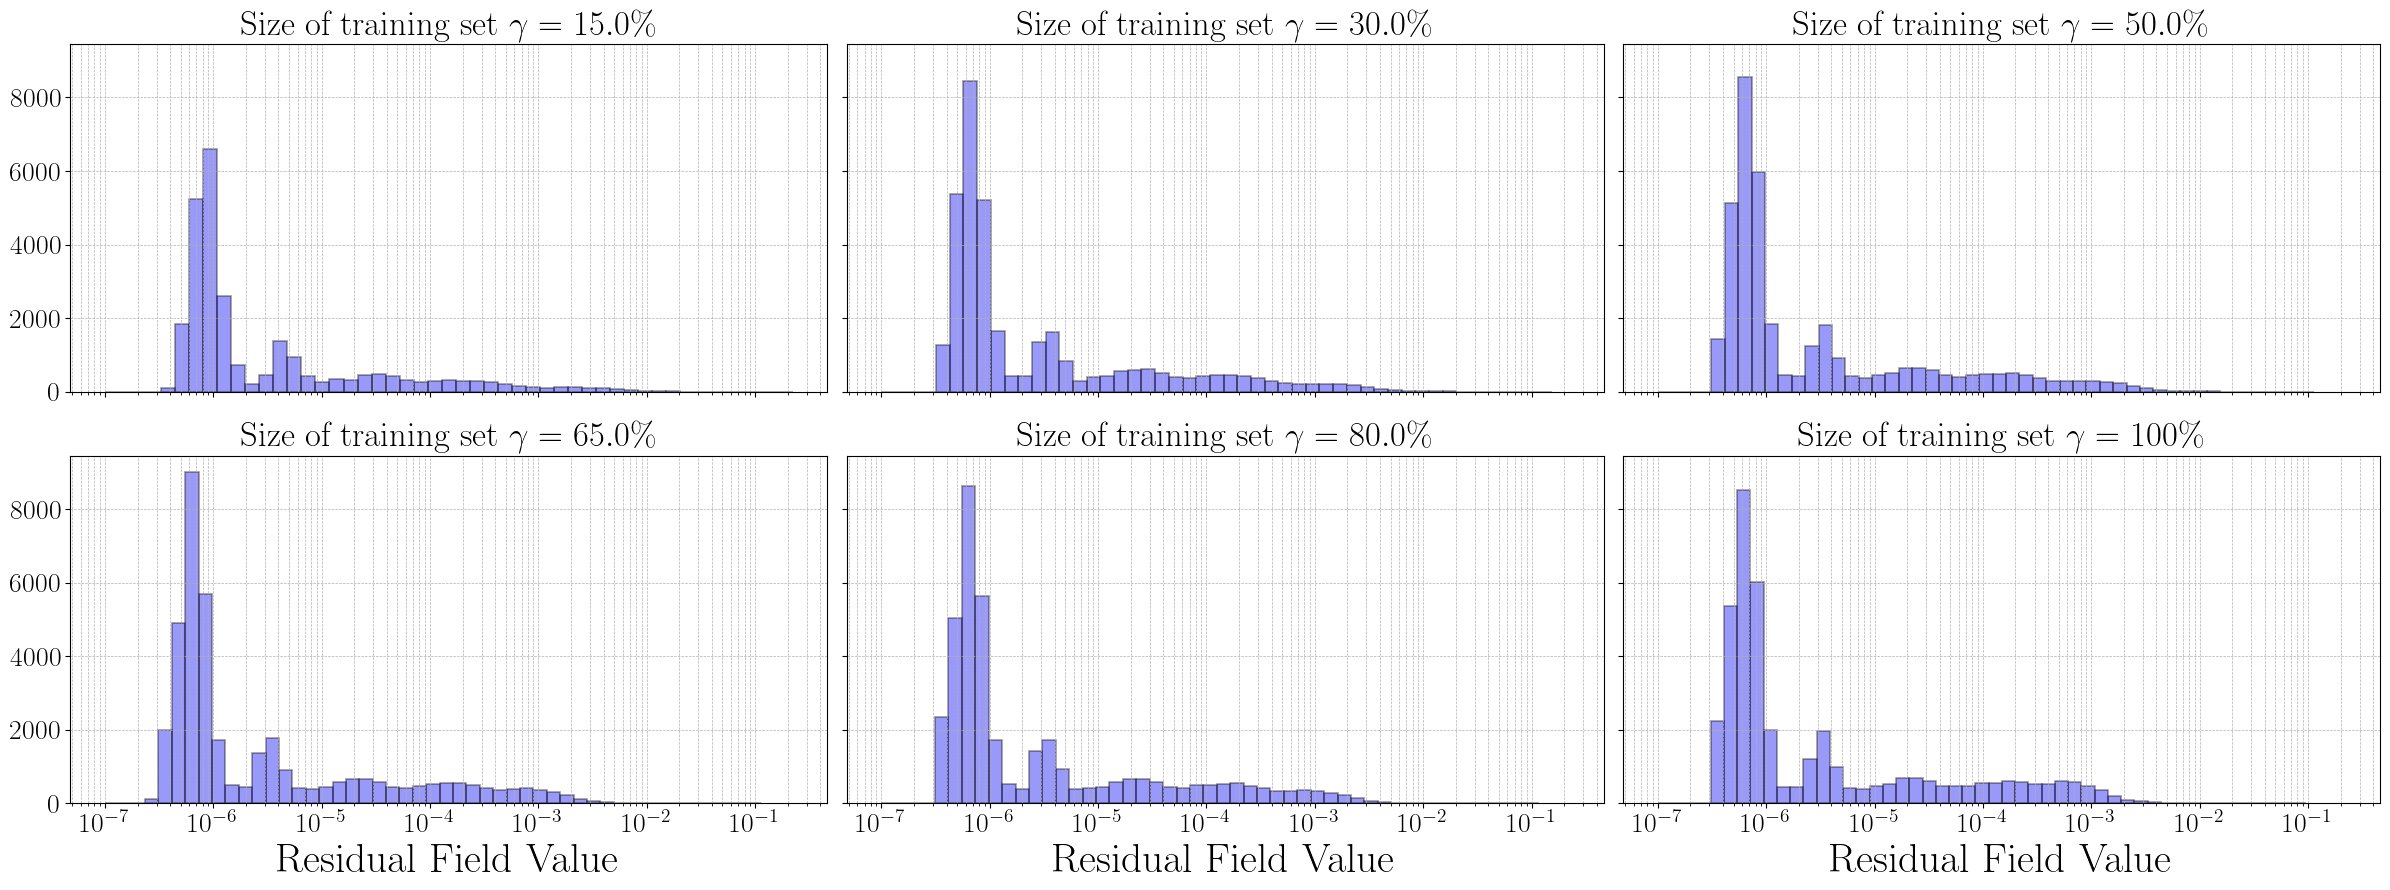

In [8]:
from matplotlib import cm
import seaborn as sns

residuals_per_condition = [errors.mean(axis=2).mean(axis=0)[i, :] for i in range(len(fractions))]

ncols = 3
nrows = 2
fig, axes = plt.subplots(nrows, ncols, figsize=(8 * ncols, 4.5 * nrows), sharey=True, sharex=True)
axes = axes.flatten()

nbins = 50

for i in range(len(residuals_per_condition)):
    ax = axes[i]

    data = residuals_per_condition[i]
    bins = np.logspace(-7, np.log10(data.max()), nbins)
    ax.hist(data, bins=bins, color=cm.jet(0.1), alpha=0.4, edgecolor='black', linewidth=1.2, density=True)

    ax.set_xscale('log')
    ax.set_title('Size of training set $\\gamma='+str(fractions[i]*100)+'$\%', fontsize=25)
    ax.grid(which='both', linestyle='--', linewidth=0.5)
    ax.tick_params(axis='both', which='major', labelsize=20)
    
    if i >= (ncols * (nrows - 1)):
        ax.set_xlabel('Residual Field Value', fontsize=30)

for i in range(len(residuals_per_condition), len(axes)):
    axes[i].axis('off')  # Hide unused subplots

plt.tight_layout()

# _line, _labels = axes[1].get_legend_handles_labels()
# axes[-1].legend(_line, _labels, framealpha=1, ncols=1, fontsize=18, loc='upper left')

fig.savefig(path_res + f'residual_hist{_stats}_{seedtest}.pdf', bbox_inches='tight', dpi=300)